# Customer Segmentation using PCA + K-Means

In [4]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

df = pd.read_csv(r"data/customer_data.csv")
print(df)

   Customer   Age   Income   Spending   Savings   OnlineOrders
0      Aman    22    25000         85      3000             18
1      Tiya    24    28000         90      2500             20
2      Neha    21    23000         80      2000             17
3     Rahul    27    32000         75      5000             15
4     Sneha    29    35000         70      7000             14
5     Arjun    26    30000         78      4500             16
6     Imran    40    65000         45     18000              8
7     Priya    42    70000         40     22000              7
8       Raj    45    75000         35     25000              6
9     Meera    38    60000         50     16000              9
10    Karan    43    72000         38     24000              6
11     Isha    39    62000         48     17000             10
12   Rakesh    55    95000         25     40000              3
13    Divya    52    90000         30     35000              4
14    Kabir    58   100000         20     45000        

# Customer শুধু নাম। ML-এর clustering-এর জন্য এটা ব্যবহার করবে না।

In [5]:
X = df.drop(columns="Customer")
print(X.head())

   Age  Income  Spending  Savings  OnlineOrders
0   22   25000        85     3000            18
1   24   28000        90     2500            20
2   21   23000        80     2000            17
3   27   32000        75     5000            15
4   29   35000        70     7000            14


In [6]:
scaled = StandardScaler()
scaled_data = scaled.fit_transform(X)
df_scaled_data = pd.DataFrame(scaled_data, columns=X.columns)
print(df_scaled_data.head())

        Age    Income  Spending   Savings  OnlineOrders
0 -1.469065 -1.415445  1.541658 -1.237075      1.516764
1 -1.306837 -1.304671  1.758793 -1.271332      1.860182
2 -1.550179 -1.489294  1.324523 -1.305589      1.345055
3 -1.063495 -1.156972  1.107388 -1.100045      1.001637
4 -0.901267 -1.046198  0.890253 -0.963015      0.829928


Variance captured by each PCA Component: 
[98.61  1.13]


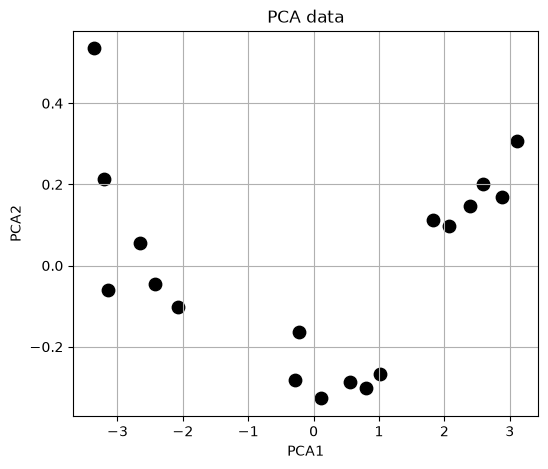

       PCA1      PCA2
0 -3.211402  0.213169
1 -3.354355  0.535109
2 -3.137788 -0.058992
3 -2.428273 -0.045882
4 -2.071078 -0.101187


In [7]:
pca = PCA(n_components=2, random_state=42)

pca_data = pca.fit_transform(scaled_data)
pca_df = pd.DataFrame(pca_data, columns=['PCA1','PCA2'])
explained_variance = pca.explained_variance_ratio_
print("Variance captured by each PCA Component: ")
print(np.round(explained_variance*100, 2))

plt.figure(figsize= (6,5))
plt.scatter(pca_df['PCA1'], pca_df['PCA2'], color= 'black', s=80)
plt.title('PCA data')
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.grid(True)
plt.show()
print(pca_df.head())

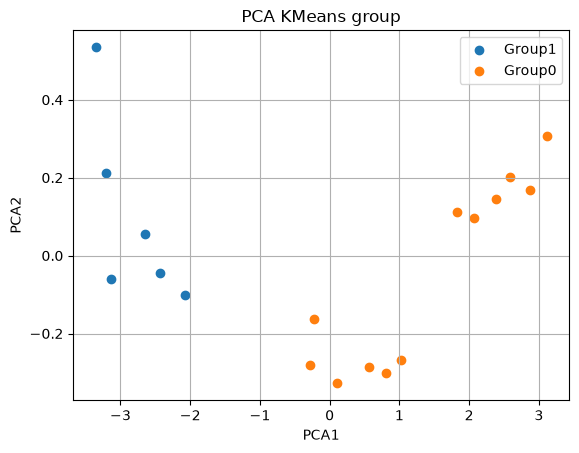

Group Data
        PCA1      PCA2  Group
6   0.107272 -0.327436      0
7   0.558568 -0.286754      0
8   1.015821 -0.268116      0
9  -0.283102 -0.282083      0
10  0.804547 -0.302093      0
11 -0.220892 -0.163729      0
12  2.592691  0.201622      0
13  2.074517  0.096948      0
14  3.110865  0.306296      0
15  2.387373  0.145601      0
16  2.874662  0.169287      0
17  1.828538  0.112286      0


In [8]:
model = KMeans(n_clusters=2, random_state=42, n_init=10)
pca_df['Group'] = model.fit_predict(pca_df[['PCA1','PCA2']])
df['Group'] = pca_df['Group'].values

for group in pca_df['Group'].unique():
    group_data = pca_df[pca_df['Group']==group]
    plt.scatter(group_data['PCA1'], group_data['PCA2'], label=f"Group{group}")

plt.title('PCA KMeans group')
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.legend()
plt.grid(True)
plt.show()

print('Group Data')
print(group_data)

In [9]:
df_0 = df[df['Group']==0]
df_1 = df[df['Group']==1]

print('\ndf 1')
print(df_0)
print('\ndf 2')
print(df_1)


df 1
   Customer   Age   Income   Spending   Savings   OnlineOrders  Group
6     Imran    40    65000         45     18000              8      0
7     Priya    42    70000         40     22000              7      0
8       Raj    45    75000         35     25000              6      0
9     Meera    38    60000         50     16000              9      0
10    Karan    43    72000         38     24000              6      0
11     Isha    39    62000         48     17000             10      0
12   Rakesh    55    95000         25     40000              3      0
13    Divya    52    90000         30     35000              4      0
14    Kabir    58   100000         20     45000              2      0
15    Pooja    54    92000         28     38000              3      0
16    Rohit    56    98000         22     42000              2      0
17   Simran    51    88000         32     33000              5      0

df 2
  Customer   Age   Income   Spending   Savings   OnlineOrders  Group
0     Ama